# Deep Network Development · Autumn 2026
## Week 6 Practice — Data Exploration
**Dataset:** Student Performance Factors · **Tools:** Pandas, NumPy, Matplotlib, SciPy, scikit-learn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load and inspect the data

Load the student dataset with `pd.read_csv()`. Key arguments:

- `sep`: column separator (`,` here)
- `header=0`: first row contains column names
- `index_col=False`: do not use a CSV column as the row index

Inspect the data types, summary statistics, and missing values.

In [3]:
df = pd.read_csv('StudentPerformanceFactors.csv', sep=',', header=0, index_col=False)
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


`df.describe()` can provide us with the descriptive statistics of the dataset.

In [4]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


`df.dtypes` shows the data type of each column. Since our regression model requires numerical inputs, we need to encode the categorical features before training.

In [5]:
df.dtypes

Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learning_Disabilities           str
Parental_Education_Level        str
Distance_from_Home              str
Gender                          str
Exam_Score                    int64
dtype: object

In [6]:
df.isna().sum(axis=0)

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

### Handle missing values
Find rows containing missing values and remove them. How many observations remain?

In [7]:
before_count = len(df.index)

In [8]:
isna = df.isna().to_numpy()

In [9]:
missing_values = np.argwhere(isna.any(axis=1)).ravel()

In [10]:
df = df.drop(index=missing_values, axis=0)

In [11]:
df.isna().sum(axis=0)

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [12]:
after_count = len(df.index)

print(f'Dataset size before cleaning: {before_count}')
print(f'Dataset size after cleaning: {after_count}')

Dataset size before cleaning: 6607
Dataset size after cleaning: 6378


### Inspect categorical features
Which columns contain text categories? What values do they represent?

In [26]:
# df[df.dtypes[df.dtypes == 'object'].index.values]
# df.select_dtypes(include='object')
df.select_dtypes(include=['object', 'string'])


,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,Low,High,No,Low,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
1,Low,Medium,No,Low,Yes,Medium,Medium,Public,Negative,No,College,Moderate,Female
2,Medium,Medium,Yes,Medium,Yes,Medium,Medium,Public,Neutral,No,Postgraduate,Near,Male
3,Low,Medium,Yes,Medium,Yes,Medium,Medium,Public,Negative,No,High School,Moderate,Male
4,Medium,Medium,Yes,Medium,Yes,Medium,High,Public,Neutral,No,College,Near,Female
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,High,Medium,No,Medium,Yes,High,Medium,Public,Positive,No,High School,Near,Female
6603,High,Medium,No,Medium,Yes,Low,High,Public,Positive,No,High School,Near,Female
6604,Medium,Low,Yes,Low,Yes,Low,Medium,Public,Negative,No,Postgraduate,Near,Female
6605,High,High,Yes,High,Yes,Low,Medium,Private,Positive,No,High School,Far,Female


## 2. Encode categorical features
Convert categories into numerical values for analysis:

- **Low / Medium / High:** `0 / 1 / 2`
- **No / Yes:** `0 / 1`
- **Public / Private:** `0 / 1`
- **Negative / Neutral / Positive:** `-1 / 0 / 1`
- **Gender:** `Male = 0.0`, other recorded category = `1.0`

For simplicity, we will remove Parental_Education_Level and Distance_from_Home.

Usually, when converting categorical features to numerical values:

- Ordinal categories: Preserve their order (Low = 0, Medium = 1, High = 2).
- Binary categories: Encode the two possible values as 0 and 1.
- Other categories: Numerical codes do not necessarily represent meaningful distances.

**Think:** How could `np.unique(..., return_counts=True)` or `np.bincount()` help verify the encoded values?

The following columns use **Low / Medium / High**: `Parental_Involvement`, `Access_to_Resources`, `Motivation_Level`, `Family_Income`, and `Teacher_Quality`.

In [27]:
columns_to_replace_range = [
    'Parental_Involvement', 
    'Access_to_Resources', 
    'Motivation_Level', 
    'Family_Income', 
    'Teacher_Quality'
]
replace_dict = {'Low': 0, 'Medium': 1, 'High': 2}

df[columns_to_replace_range] = df[columns_to_replace_range].apply(lambda col: col.map(replace_dict))

In [28]:
df.drop(columns=['Parental_Education_Level', 'Distance_from_Home'], inplace=True)

In [29]:
df['School_Type'] = df['School_Type'].apply(lambda x: 0 if x == 'Public' else 1)

In [30]:
columns_to_replace_yes_no = [
    'Extracurricular_Activities', 
    'Internet_Access',
    'Learning_Disabilities'
]

df[columns_to_replace_yes_no] = df[columns_to_replace_yes_no].apply(
    lambda col: col.map({'No': 0, 'Yes': 1})
)

In [31]:
replace_dict = {'Negative': -1, 'Neutral': 0, 'Positive': 1}
df['Peer_Influence'] = df['Peer_Influence'].apply(lambda col: replace_dict.get(col, 0))

In [32]:
df['Gender'] = df['Gender'].apply(lambda x: 0.0 if x == 'Male' else 1.0)

In [35]:
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Gender,Exam_Score
0,23,84,0,2,0,7,73,0,1,0,0,1,0,1,3,0,0.0,67
1,19,64,0,1,0,8,59,0,1,2,1,1,0,-1,4,0,1.0,61
2,24,98,1,1,1,7,91,1,1,2,1,1,0,0,4,0,0.0,74
3,29,89,0,1,1,8,98,1,1,1,1,1,0,-1,4,0,0.0,71
4,19,92,1,1,1,6,65,1,1,3,1,2,0,0,4,0,1.0,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,2,1,0,7,76,1,1,1,2,1,0,1,2,0,1.0,68
6603,23,76,2,1,0,8,81,1,1,3,0,2,0,1,2,0,1.0,69
6604,20,90,1,0,1,6,65,0,1,3,0,1,0,-1,2,0,1.0,68
6605,10,86,2,2,1,6,91,2,1,2,0,1,1,1,3,0,1.0,68


## 3. Visualize distributions
Start with category frequencies and exam-score counts, then group scores into broader intervals.

<Axes: title={'center': 'Gender Distribution'}, xlabel='Index', ylabel='Gender'>

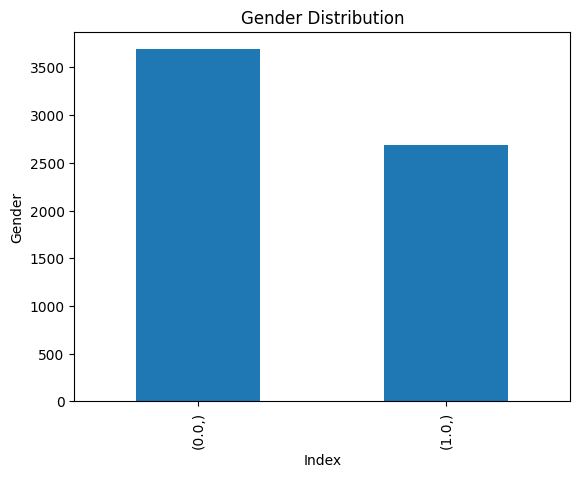

In [36]:
df[['Gender']].value_counts().plot(kind='bar', title='Gender Distribution', xlabel='Index', ylabel='Gender', legend=False)

<Axes: title={'center': 'Exam Score Distribution'}, xlabel='Index', ylabel='Exam Score'>

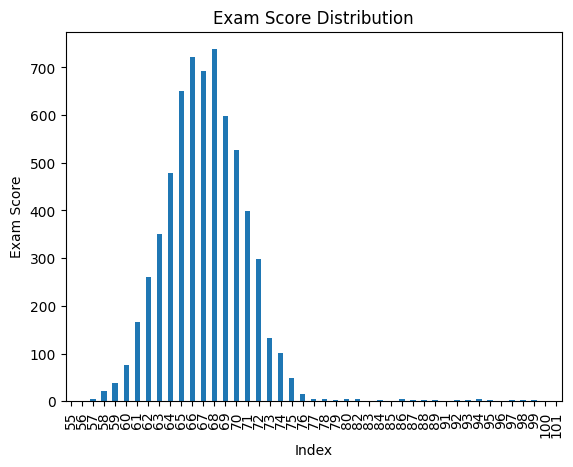

In [37]:
df['Exam_Score'].value_counts().sort_index().plot(kind='bar', title='Exam Score Distribution', xlabel='Index', ylabel='Exam Score', legend=False)

**Illustrative letter-grade bands** (not labels supplied by the dataset):

| Grade | Score | Interpretation |
|:--|:--|:--|
| A | 90–100 | Excellent |
| B | 80–89 | Good |
| C | 70–79 | Satisfactory |
| D | 60–69 | Minimum passing |
| F | Below 60 | Failing |

In [38]:
exam_scores = df['Exam_Score'].to_numpy()

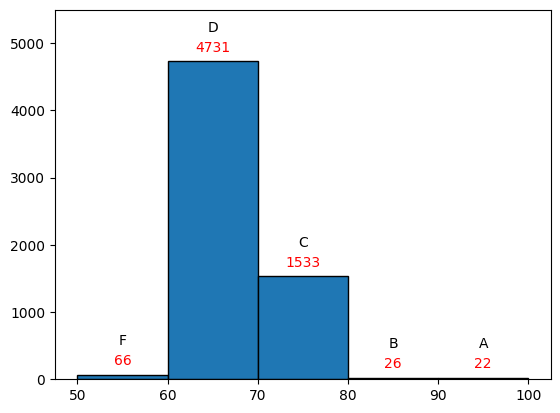

In [39]:
hist = np.histogram(exam_scores, bins=[50, 60, 70, 80, 90, 101])

fig, ax = plt.subplots()

plt.bar(hist[1][:-1], hist[0], width=10, edgecolor='black', align='edge')
plt.ylim(0, 5500)

letters = ['F', 'D', 'C', 'B', 'A']
for i in range(len(hist[0])):
    plt.text(hist[1][i] + 5, hist[0][i] + 400, letters[i], ha='center', va='bottom')
    plt.text(hist[1][i] + 5, hist[0][i] + 100, str(hist[0][i]), ha='center', va='bottom', color='red')

### Sleep and exam scores
Inspect the scatter plot. Is there an obvious relationship? **Association does not establish causation.**

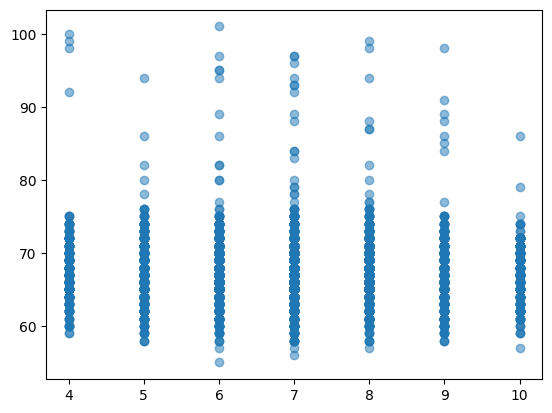

In [40]:
plt.scatter(df['Sleep_Hours'], df['Exam_Score'], alpha=0.5)

### Study time and exam scores
Does this scatter plot suggest a stronger relationship?

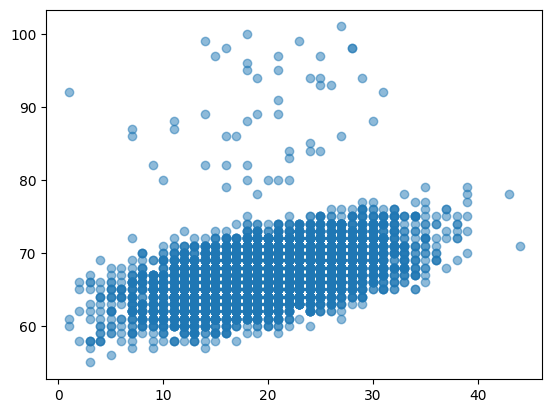

In [41]:
plt.scatter(df['Hours_Studied'], df['Exam_Score'], alpha=0.5)

Scatter plots are useful, but checking every feature pair individually is slow. Correlation coefficients provide a compact numerical summary.

## 4. Correlation analysis

**Optional enrichment:** Correlation analysis is included to connect exploratory data analysis with later machine-learning topics; it is not examinable in this course.

In [42]:
from scipy.stats import pearsonr, spearmanr

In [43]:
columns = df.columns.values

In [44]:
columns

<StringArray>
[             'Hours_Studied',                 'Attendance',
       'Parental_Involvement',        'Access_to_Resources',
 'Extracurricular_Activities',                'Sleep_Hours',
            'Previous_Scores',           'Motivation_Level',
            'Internet_Access',          'Tutoring_Sessions',
              'Family_Income',            'Teacher_Quality',
                'School_Type',             'Peer_Influence',
          'Physical_Activity',      'Learning_Disabilities',
                     'Gender',                 'Exam_Score']
Length: 18, dtype: str

In [45]:
num_cols = len(columns)

### Pearson correlation

Pearson's correlation coefficient measures the strength and direction of a linear relationship between two variables. Its values range from −1 to 1. A value near 0 indicates weak linear association. For ordinal variables encoded as 0, 1, 2, Pearson correlation assumes equal distances between consecutive categories.

In [46]:
pcorr = np.zeros((num_cols, num_cols))
pp_val = np.zeros((num_cols, num_cols))

for i, col1 in enumerate(columns):
    for j, col2 in enumerate(columns):
        c, p = pearsonr(df[col1], df[col2])
        pcorr[i, j] = c
        pp_val[i, j] = p

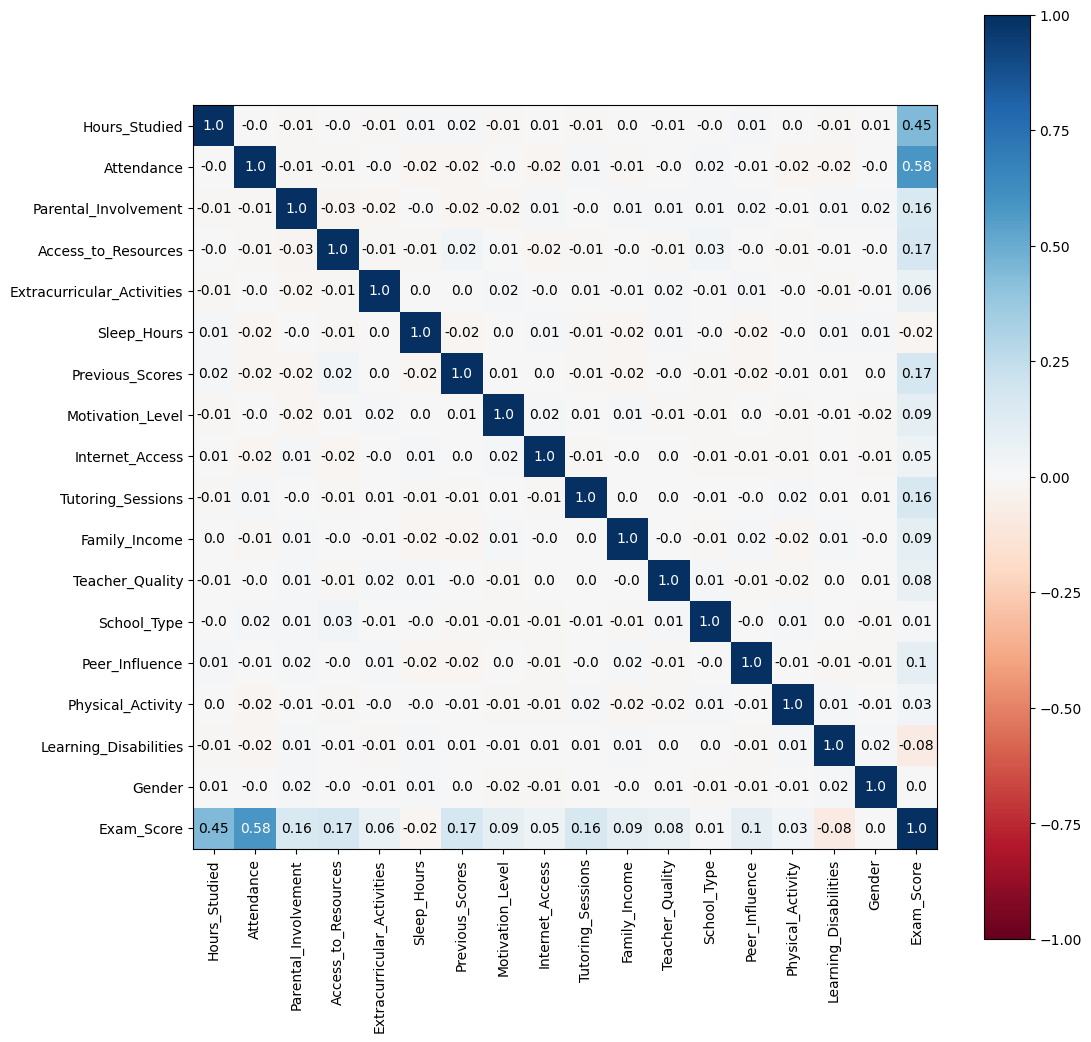

In [47]:
fig, ax = plt.subplots(figsize=(12, 12))

im = ax.imshow(pcorr, cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(num_cols), labels=columns, rotation=90)
ax.set_yticks(range(num_cols), labels=columns)
cbar = ax.figure.colorbar(im, ax=ax)


for i in range(num_cols):
    for j in range(num_cols):
        color = 'black' if pcorr[i, j] < 0.5 and pcorr[i, j] > -0.5 else 'white'
        text = ax.text(j, i, pcorr[i, j].round(2),
                       ha="center", va="center", color=color)

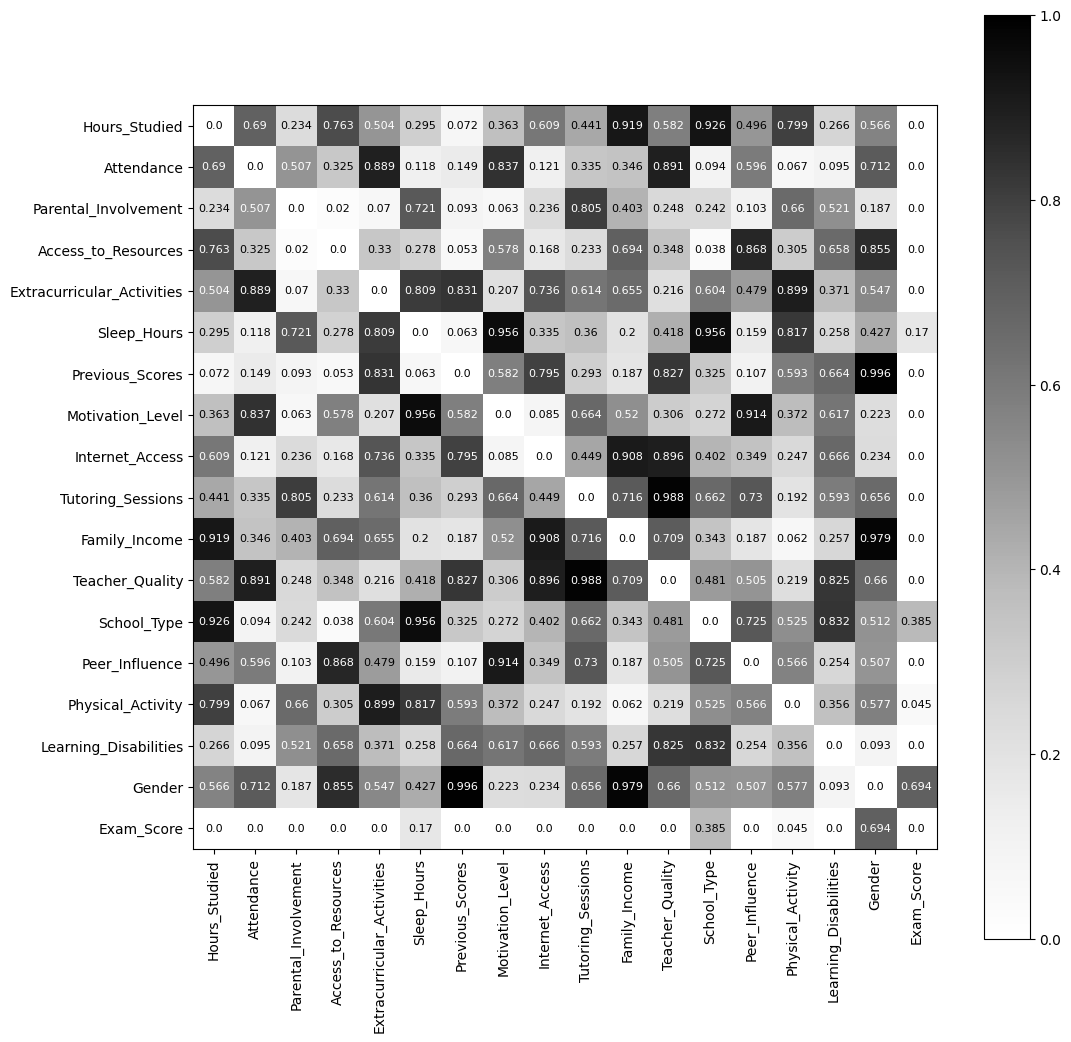

In [48]:
fig, ax = plt.subplots(figsize=(12, 12))

im = ax.imshow(pp_val, cmap='Greys', vmin=0, vmax=1)
ax.set_xticks(range(num_cols), labels=columns, rotation=90)
ax.set_yticks(range(num_cols), labels=columns)
cbar = ax.figure.colorbar(im, ax=ax)

for i in range(num_cols):
    for j in range(num_cols):
        color = 'black' if pp_val[i, j] < 0.5 else 'white'
        text = ax.text(j, i, pp_val[i, j].round(3),
                       ha="center", va="center", color=color, fontsize=8)

### Spearman rank correlation
Measures **monotonic association** using ranks. Compare its results with Pearson: which relationships change most?

In [49]:
scorr = np.zeros((num_cols, num_cols))
sp_val = np.zeros((num_cols, num_cols))

for i, col1 in enumerate(columns):
    for j, col2 in enumerate(columns):
        c, p = spearmanr(df[col1], df[col2])
        scorr[i, j] = c
        sp_val[i, j] = p

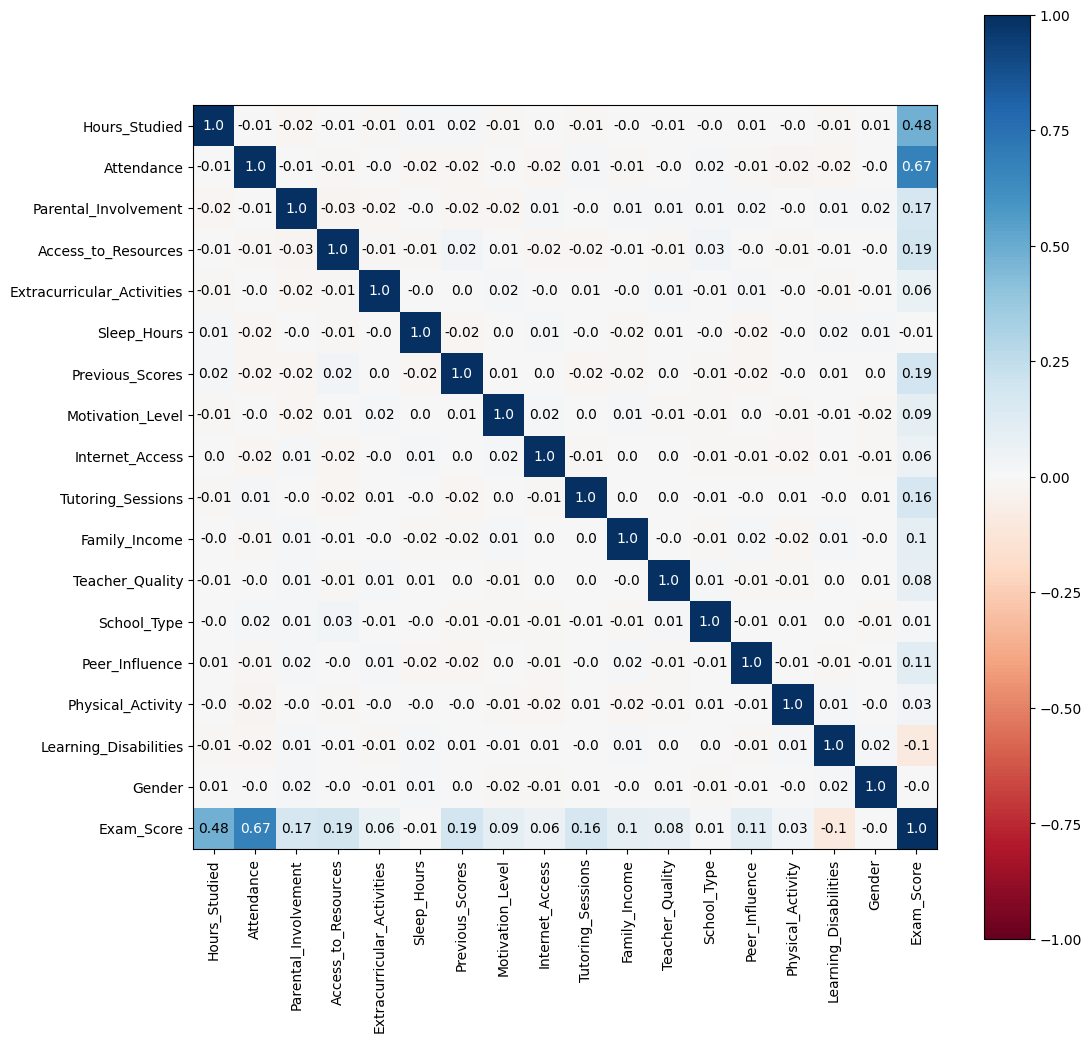

In [50]:
fig, ax = plt.subplots(figsize=(12, 12))

im = ax.imshow(scorr, cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(num_cols), labels=columns, rotation=90)
ax.set_yticks(range(num_cols), labels=columns)
cbar = ax.figure.colorbar(im, ax=ax)

for i in range(num_cols):
    for j in range(num_cols):
        color = 'black' if scorr[i, j] < 0.5 and scorr[i, j] > -0.5 else 'white'
        text = ax.text(j, i, scorr[i, j].round(2),
                       ha="center", va="center", color=color)

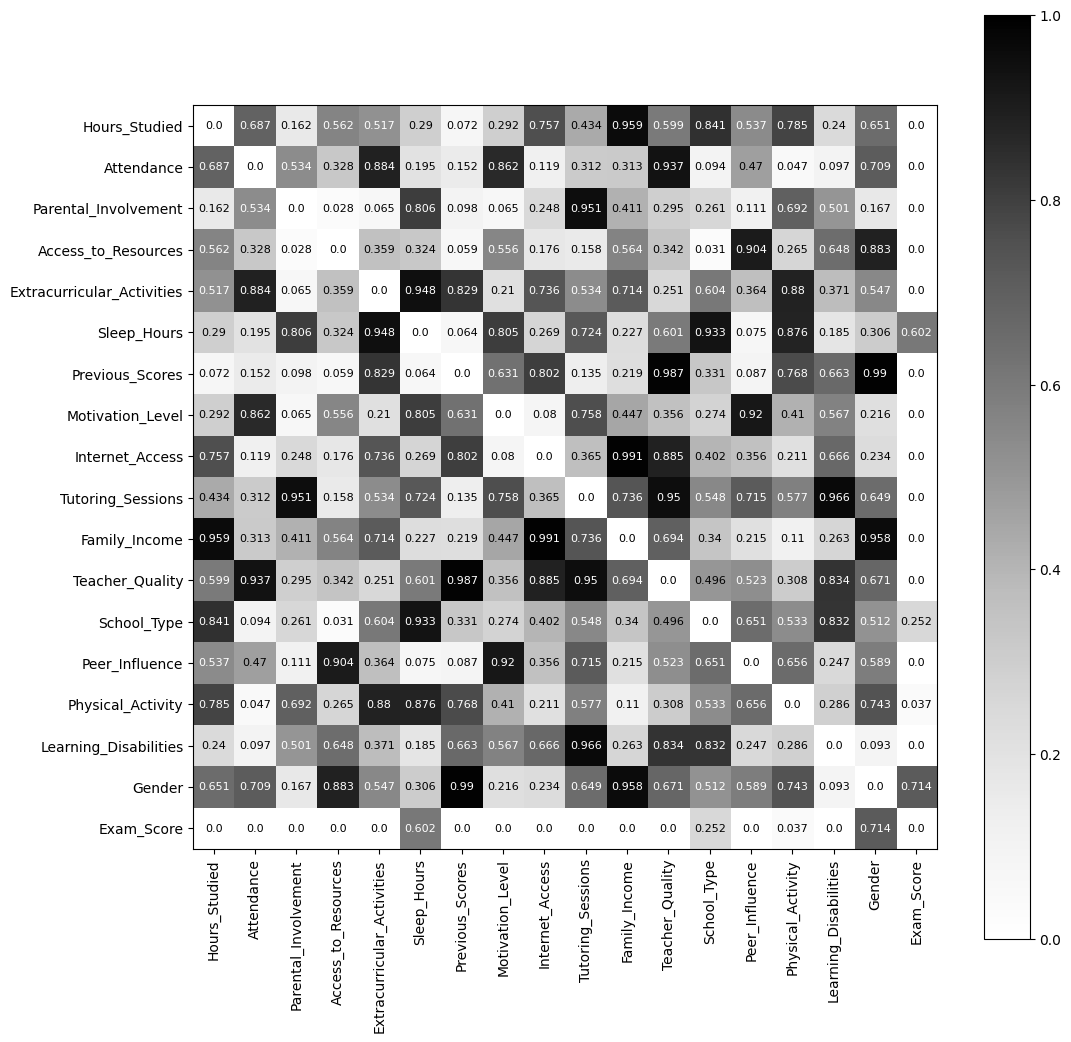

In [51]:
fig, ax = plt.subplots(figsize=(12, 12))

im = ax.imshow(sp_val, cmap='Greys', vmin=0, vmax=1)
ax.set_xticks(range(num_cols), labels=columns, rotation=90)
ax.set_yticks(range(num_cols), labels=columns)
cbar = ax.figure.colorbar(im, ax=ax)

for i in range(num_cols):
    for j in range(num_cols):
        color = 'black' if sp_val[i, j] < 0.5 else 'white'
        text = ax.text(j, i, sp_val[i, j].round(3), ha="center", va="center", color=color, fontsize=8)

## 5. Select candidate features
We want to predict `Exam_Score`. Use correlation as an initial screening tool, not as definitive proof that a feature is useful.

In [52]:
column_names = df.columns.values[:-1] 

In [53]:
exam_score_col = df.columns.values[-1]

In [54]:
column_names.shape

(17,)

In [55]:
df_np = df.to_numpy()
df_np.shape

(6378, 18)

Rank features by the **absolute Pearson correlation** with `Exam_Score`, then choose the top 2, 5, 7, 10 and all of the features. Which features appear most informative?

**Evaluation note:** Selecting features using target correlations from the full dataset can leak information into the test set. For a fair predictive comparison, repeat supervised selection using only training data.

In [56]:
exam_score_corr = pcorr[-1, :-1]

In [57]:
indices = np.argsort(np.abs(exam_score_corr))[::-1]

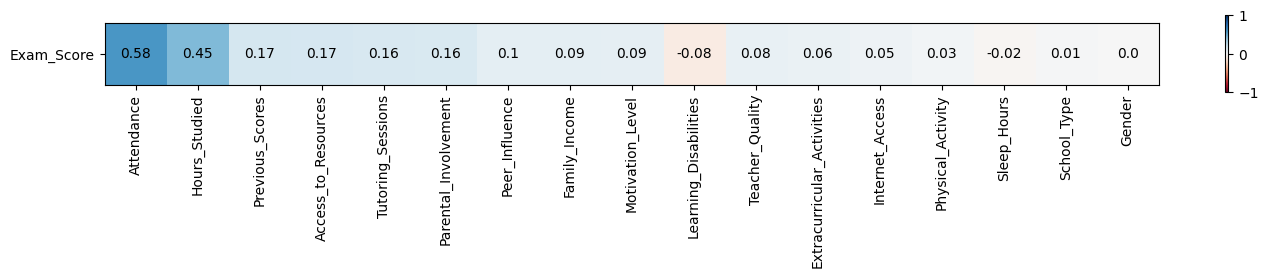

In [58]:
fig, ax = plt.subplots(figsize=(17, 1))

im = ax.imshow(exam_score_corr[None, indices], cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(len(column_names)), labels=column_names[indices], rotation=90)
ax.set_yticks(range(1), labels=[exam_score_col])
cbar = ax.figure.colorbar(im, ax=ax)

for j in range(len(indices)):
    text = ax.text(j, 0, exam_score_corr[indices[j]].round(2), ha="center", va="center", color='black')

In [60]:
top_2_cols = column_names[indices][:2]
top_5_cols = column_names[indices][:5]
top_7_cols = column_names[indices][:7]
top_10_cols = column_names[indices][:10]
all_features_cols = column_names

In [61]:
top_2_cols

<StringArray>
['Attendance', 'Hours_Studied']
Length: 2, dtype: str

In [62]:
top_5_cols

<StringArray>
[         'Attendance',       'Hours_Studied',     'Previous_Scores',
 'Access_to_Resources',   'Tutoring_Sessions']
Length: 5, dtype: str

In [63]:
top_7_cols

<StringArray>
[          'Attendance',        'Hours_Studied',      'Previous_Scores',
  'Access_to_Resources',    'Tutoring_Sessions', 'Parental_Involvement',
       'Peer_Influence']
Length: 7, dtype: str

In [64]:
top_10_cols

<StringArray>
[           'Attendance',         'Hours_Studied',       'Previous_Scores',
   'Access_to_Resources',     'Tutoring_Sessions',  'Parental_Involvement',
        'Peer_Influence',         'Family_Income',      'Motivation_Level',
 'Learning_Disabilities']
Length: 10, dtype: str

In [65]:
all_features = df[all_features_cols].to_numpy()
top_10_features = df[top_10_cols].to_numpy()
top_7_features = df[top_7_cols].to_numpy()
top_5_features = df[top_5_cols].to_numpy()
top_2_features = df[top_2_cols].to_numpy()

exam_scores = df['Exam_Score'].to_numpy()

## 6. Train linear regression models
Compare models using different numbers of selected features. More predictors do not always mean better performance.

In [66]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

### Split training and test data
Train on one subset and evaluate on held-out observations. Keep the test set out of model-development decisions.

In [67]:
train_idxs, test_idxs = train_test_split(np.arange(all_features.shape[0]), test_size=0.2, random_state=42)

train_idxs.shape, test_idxs.shape

((5102,), (1276,))

### Fit the regression models
Train one model for each feature subset. What changes as more predictors are included?

In [68]:
all_lr = LinearRegression().fit(all_features[train_idxs], exam_scores[train_idxs])
top_10_lr = LinearRegression().fit(top_10_features[train_idxs], exam_scores[train_idxs])
top_7_lr = LinearRegression().fit(top_7_features[train_idxs], exam_scores[train_idxs])
top_5_lr = LinearRegression().fit(top_5_features[train_idxs], exam_scores[train_idxs])
top_2_lr = LinearRegression().fit(top_2_features[train_idxs], exam_scores[train_idxs])

### Evaluate predictions
Use **root mean squared error (RMSE)**. Lower is better; the result is in exam-score points.

In [69]:
all_rmse = root_mean_squared_error(all_lr.predict(all_features[test_idxs]), exam_scores[test_idxs])
top_10_rmse = root_mean_squared_error(top_10_lr.predict(top_10_features[test_idxs]), exam_scores[test_idxs])
top_7_rmse = root_mean_squared_error(top_7_lr.predict(top_7_features[test_idxs]), exam_scores[test_idxs])
top_5_rmse = root_mean_squared_error(top_5_lr.predict(top_5_features[test_idxs]), exam_scores[test_idxs])
top_2_rmse = root_mean_squared_error(top_2_lr.predict(top_2_features[test_idxs]), exam_scores[test_idxs])

### Compare test RMSE
Which model performs best on held-out data? Are the differences substantial?

(0.0, 4.0)

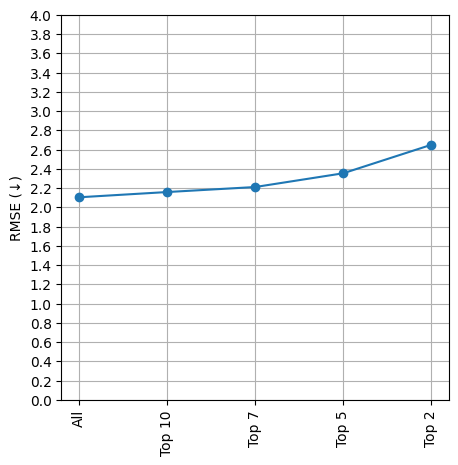

In [70]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.plot(range(5), [all_rmse, top_10_rmse, top_7_rmse, top_5_rmse, top_2_rmse], marker='o')
ax.set_xticks(range(5), labels=['All', 'Top 10', 'Top 7', 'Top 5', 'Top 2'], rotation=90)
ax.set_yticks(np.linspace(0, 4, 21))
ax.set_ylabel('RMSE (↓)')
ax.grid()
ax.set_ylim(0, 4)

### Visualize the two-feature model
Plot exam scores against each predictor. For each line, **hold the other predictor at its training-set mean**. These are conditional predictions from one two-feature model.

In [71]:
top_2_cols

<StringArray>
['Attendance', 'Hours_Studied']
Length: 2, dtype: str

The trained model's parameters can be extracted using ```coef_``` for the weight/slope associated with each feature and ```intercept_``` for the bias/y-intercept.

In [72]:
att, hours = top_2_lr.coef_
intercept = top_2_lr.intercept_

In [73]:
att, hours, intercept

(np.float64(0.1966465396249366),
 np.float64(0.2934075083087232),
 np.float64(45.656718069056))

Text(0, 0.5, 'Exam Score')

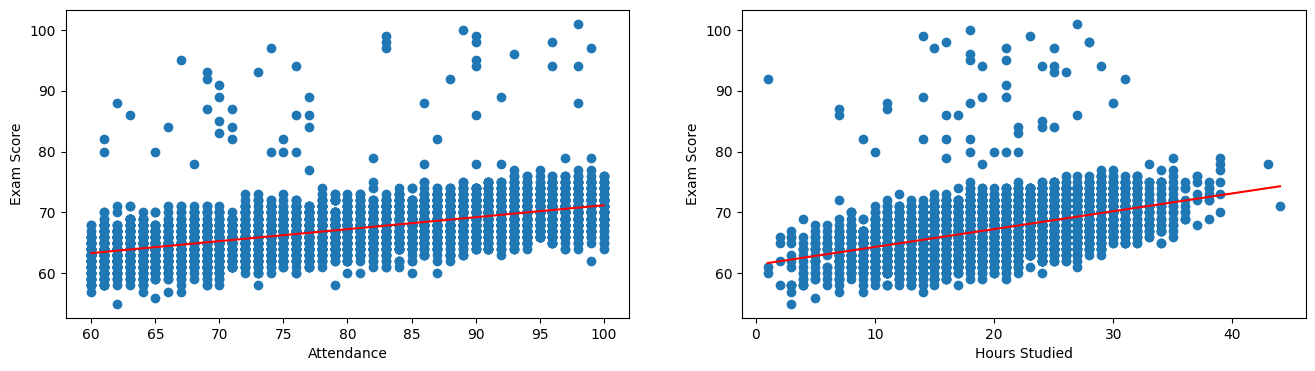

In [74]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 4))

mean_hours = top_2_features[train_idxs, 1].mean()
x = np.linspace(
    df['Attendance'].min(),
    df['Attendance'].max(),
    100
)
y = intercept + att * x + hours * mean_hours

ax[0].scatter(df['Attendance'], df['Exam_Score'])
ax[0].set_xlabel('Attendance')
ax[0].set_ylabel('Exam Score')
ax[0].plot(x, y, color='red')

mean_att = top_2_features[train_idxs, 0].mean()
x = np.linspace(
    df['Hours_Studied'].min(),
    df['Hours_Studied'].max(),
    100
)
y = intercept + att * mean_att + hours * x

ax[1].scatter(df['Hours_Studied'], df['Exam_Score'])
ax[1].plot(x, y, color='red')
ax[1].set_xlabel('Hours Studied')
ax[1].set_ylabel('Exam Score')

## Bonus Task 1 · Standardization
Standardize predictors and retrain the **all / top 10 / top 7 / top 5 / top 2** models. Compare test RMSE with the original models.

**Question:** Why are ordinary least-squares predictions nearly unchanged when predictors are rescaled?

**Method note:** In a leakage-free workflow, fit `StandardScaler` on the training set only, then transform the test set with that same fitted scaler.

In [ ]:
# target_col = 'Exam_score'
fig, ax = plt.subplots(figsize=(17, 1))

im = ax.imshow
ax.set yticks
ax.set xticks


## Bonus Task 2 · Comparing Regression Coefficients

Compare the coefficients of the original and standardized regression models.

1. Rank the features by the absolute magnitude of their coefficients.
2. Compare the rankings before and after standardization.
3. Explain why the rankings may differ.
4. Compare the standardized coefficient rankings with the Pearson correlation rankings.